# 7. Boundary layers and external flow

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 5

Every chapter so far has taken the heat transfer coefficient $h$ as given. Chapter 1 took
$h = 25$ W/(m² K) for the district-heating pipe in winter air without saying where the
number came from. This chapter derives $h$ from the flow. Fluid sticks to a surface, so a
thin *boundary layer* forms in which the velocity rises from zero to that of the stream,
and through which heat must be conducted. The thinner the layer, the larger $h$.

The questions are practical. What heat transfer coefficient does a wind of a given speed
give the pipe of Chapter 1, and how much does the wind change its heat loss? Exact
solutions for a flat plate show where the familiar formulas come from; a correlation built
on experiments handles the cylinder. Two independent numerical solutions check the exact
ones: a collocation solution of the similarity equations, and a marching solution of the
full boundary-layer equations that makes no similarity assumption at all.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import convection_ext, numerics, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_ext, numerics, properties, reference
from engtransport.constants import SIGMA_SB
from engtransport.plotting import panel_label, use_style

use_style()

## 7.1 The boundary layer and its thickness

A stream of velocity $U$ meets a flat plate edge-on. At a distance $x$ from the leading
edge, viscosity has had a time of order $x/U$ to spread the effect of the wall, so the
layer has grown to a thickness of order $\sqrt{\nu x/U}$:

$$
\frac{\delta}{x} \sim \frac{1}{\sqrt{\mathrm{Re}_x}}, \qquad \mathrm{Re}_x = \frac{Ux}{\nu} .
\tag{7.1}
$$

Heat diffuses with $\alpha = \nu/\mathrm{Pr}$ instead of $\nu$, so the thermal layer has its
own thickness $\delta_T$. For $\mathrm{Pr} \gtrsim 1$ it lies inside the velocity layer,
where the velocity near the wall grows linearly with distance from it; balancing
convection against conduction there gives $\delta_T/\delta \sim \mathrm{Pr}^{-1/3}$. For
$\mathrm{Pr} \ll 1$ (liquid metals) it is much thicker than the velocity layer, the fluid in
it moves at nearly $U$, and $\delta_T/\delta \sim \mathrm{Pr}^{-1/2}$. The heat crosses the
thermal layer by conduction, so $h \sim k/\delta_T$, and in terms of the Nusselt number
$\mathrm{Nu}_x = hx/k$:

$$
\mathrm{Nu}_x \sim \mathrm{Re}_x^{1/2}\,\mathrm{Pr}^{1/3} \quad (\mathrm{Pr} \gtrsim 1), \qquad
\mathrm{Nu}_x \sim \mathrm{Re}_x^{1/2}\,\mathrm{Pr}^{1/2} \quad (\mathrm{Pr} \ll 1) .
\tag{7.2}
$$

Two consequences matter in practice. The coefficient falls along the plate as $x^{-1/2}$:
the leading edge, where the layer is thin, transfers heat best. And $h$ grows only as the
square root of the velocity: doubling the wind raises $h$ by 40 %.

## 7.2 Exact solutions: Blasius and Pohlhausen

The scaling (7.1) suggests that the velocity profile has the same shape at every $x$ when
plotted against $\eta = y\sqrt{U/\nu x}$. With a stream function $\psi = \sqrt{\nu U x}\,
f(\eta)$, so that $u/U = f'(\eta)$, the boundary-layer equations reduce to Blasius's
ordinary differential equation,

$$
f''' + \tfrac12 f f'' = 0, \qquad f(0) = f'(0) = 0, \quad f'(\infty) = 1 .
\tag{7.3}
$$

Its solution gives the wall shear, $f''(0) = 0.33206$, and so the local friction
coefficient $C_{f,x} = 0.664\,\mathrm{Re}_x^{-1/2}$. For a wall at $T_w$ and a stream at
$T_\infty$, the temperature $\theta = (T - T_w)/(T_\infty - T_w)$ also depends on $\eta$ alone
(Pohlhausen):

$$
\theta'' + \tfrac{\mathrm{Pr}}{2}\, f\,\theta' = 0, \qquad \theta(0) = 0, \quad \theta(\infty) = 1 .
\tag{7.4}
$$

Equation (7.4) is linear in $\theta$ once $f$ is known, and integrates twice:

$$
\frac{\mathrm{Nu}_x}{\mathrm{Re}_x^{1/2}} = \theta'(0) =
\left[\int_0^\infty \exp\left(-\frac{\mathrm{Pr}}{2}\int_0^\eta f\,d\eta'\right) d\eta\right]^{-1} .
\tag{7.5}
$$

`convection_ext.solve_blasius` solves Eq. (7.3) by shooting on $f''(0)$, and
`convection_ext.pohlhausen_heat_transfer` evaluates Eq. (7.5). Over the usual range of
gases and liquids the result is fitted by the formula found in every textbook,

$$
\mathrm{Nu}_x = 0.332\,\mathrm{Re}_x^{1/2}\,\mathrm{Pr}^{1/3}, \qquad
\overline{\mathrm{Nu}}_L = 0.664\,\mathrm{Re}_L^{1/2}\,\mathrm{Pr}^{1/3} ,
\tag{7.6}
$$

where the average over a plate of length $L$ is twice the local value at its end.

In [2]:
bl = convection_ext.solve_blasius(eta_max=10.0, n_steps=2000)
print(f"Blasius: f''(0) = {bl['fpp0']:.6f}; u = 0.99 U at eta = {np.interp(0.99, bl['fp'], bl['eta']):.2f};"
      f" displacement constant {bl['eta'][-1] - bl['f'][-1]:.4f}")
Prs = np.logspace(-2, 3, 26)
exact = np.array([convection_ext.pohlhausen_heat_transfer(Pr) for Pr in Prs])
for Pr in (0.01, 0.71, 7.0, 100.0):
    e = convection_ext.pohlhausen_heat_transfer(Pr)
    print(f"Pr = {Pr:6.2f}: Nu_x/Re_x^1/2 = {e:.4f}; 0.332 Pr^1/3 = {0.332 * Pr ** (1 / 3):.4f} ({0.332 * Pr ** (1 / 3) / e - 1:+.1%})")

Blasius: f''(0) = 0.332057; u = 0.99 U at eta = 4.91; displacement constant 1.7208


Pr =   0.01: Nu_x/Re_x^1/2 = 0.0516; 0.332 Pr^1/3 = 0.0715 (+38.6%)
Pr =   0.71: Nu_x/Re_x^1/2 = 0.2942; 0.332 Pr^1/3 = 0.2962 (+0.7%)


Pr =   7.00: Nu_x/Re_x^1/2 = 0.6459; 0.332 Pr^1/3 = 0.6351 (-1.7%)
Pr = 100.00: Nu_x/Re_x^1/2 = 1.5719; 0.332 Pr^1/3 = 1.5410 (-2.0%)


For air ($\mathrm{Pr} = 0.71$) and water the fitted formula (7.6) is within 1–2 % of the
exact result, and the velocity reaches 99 % of the stream at $\eta = 4.9$, which is the
usual definition $\delta = 4.9\,x/\sqrt{\mathrm{Re}_x}$. For liquid metals
($\mathrm{Pr} = 0.01$) Eq. (7.6) is 39 % too high: the thermal layer then sees the outer,
nearly uniform flow, as the scaling (7.2) said.

## 7.3 Turbulence

At $\mathrm{Re}_x$ of a few hundred thousand the laminar layer becomes unstable and turns
turbulent. Eddies then carry heat across the layer far faster than conduction, and the
local Nusselt number becomes $\mathrm{Nu}_x = 0.0296\,\mathrm{Re}_x^{4/5}\mathrm{Pr}^{1/3}$, an
empirical result. Averaged over a plate that is laminar up to $\mathrm{Re}_c = 5 \times
10^5$ and turbulent after it,

$$
\overline{\mathrm{Nu}}_L = \left(0.037\,\mathrm{Re}_L^{4/5} - 871\right)\mathrm{Pr}^{1/3} .
\tag{7.7}
$$

The transition point is not a property of the flow alone: a rough edge or a gusty wind
moves it upstream, and outdoors flows are usually turbulent from near the edge.

## 7.4 A cylinder in a cross wind: the pipe of Chapter 1

On a cylinder the boundary layer starts at the front stagnation point, grows round the
sides and separates before the back, leaving a turbulent wake. No simple exact solution
covers this, and engineers use correlations fitted to many experiments. That of Churchill
and Bernstein covers all Reynolds and Prandtl numbers met in practice:

$$
\overline{\mathrm{Nu}}_D = 0.3 + \frac{0.62\,\mathrm{Re}_D^{1/2}\mathrm{Pr}^{1/3}}
{\left[1 + (0.4/\mathrm{Pr})^{2/3}\right]^{1/4}}
\left[1 + \left(\frac{\mathrm{Re}_D}{282\,000}\right)^{5/8}\right]^{4/5} ,
\tag{7.8}
$$

with properties at the film temperature, the mean of the surface and stream. It fits the
data to about ±20 %.

The insulated pipe of Chapter 1 has a cladding 214 mm across, nearly at the temperature of
the −35 °C air:

In [3]:
T_air = 273.15 - 35.0
air = properties.dry_air_properties(T_air + 2.0)          # film temperature, about 2 K above the air
D_clad, D_bare = 2 * 0.10715, 0.1143
h_wind = lambda V, D: convection_ext.nu_cylinder_churchill_bernstein(V * D / air["nu"], air["Pr"]) * air["k"] / D
print(f"air at {T_air + 2 - 273.15:.0f} C: nu = {air['nu']:.3e} m2/s, k = {air['k']:.4f} W/(m K), Pr = {air['Pr']:.3f}")
for V in (1.0, 3.0, 6.0, 10.0, 20.0):
    print(f"wind {V:4.0f} m/s: Re = {V * D_clad / air['nu']:8.0f}, h = {h_wind(V, D_clad):5.1f} W/(m2 K)"
          f" (bare steel pipe {h_wind(V, D_bare):5.1f})")
V25 = brentq(lambda V: h_wind(V, D_clad) - 25.0, 0.1, 50.0)
print(f"h = 25 W/(m2 K), as assumed in Chapter 1, needs a wind of {V25:.1f} m/s")

air at -33 C: nu = 1.056e-05 m2/s, k = 0.0218 W/(m K), Pr = 0.716
wind    1 m/s: Re =    20289, h =   8.2 W/(m2 K) (bare steel pipe  10.7)
wind    3 m/s: Re =    60868, h =  15.9 W/(m2 K) (bare steel pipe  20.2)
wind    6 m/s: Re =   121736, h =  25.1 W/(m2 K) (bare steel pipe  31.0)
wind   10 m/s: Re =   202893, h =  36.0 W/(m2 K) (bare steel pipe  43.5)
wind   20 m/s: Re =   405786, h =  60.5 W/(m2 K) (bare steel pipe  70.7)
h = 25 W/(m2 K), as assumed in Chapter 1, needs a wind of 6.0 m/s


The coefficient of Chapter 1 corresponds to a steady wind of 6 m/s; on a calm day it is
nearer 10 W/(m² K), and in a winter storm of 20 m/s it is 60 W/(m² K). The smaller bare
pipe has a larger $h$ at the same wind, because its boundary layer is thinner.

How much does this matter? The surface temperature, and so the heat loss, follows from
the energy balance of Chapter 1 with $h$ from Eq. (7.8):

In [4]:
r_w, r_ins, k_ins, eps, T_w = 0.05715, 0.10715, 0.045, 0.9, 273.15 + 110.0


def heat_loss(V, insulated=True):
    """Heat loss per metre: insulated pipe (Chapter 1) or the bare pipe, for a wind V."""
    if insulated:
        r_out, R_ins = r_ins, math.log(r_ins / r_w) / (2 * math.pi * k_ins)
    else:
        r_out, R_ins = r_w, 0.0
    h = h_wind(V, 2 * r_out)
    A = 2 * math.pi * r_out
    out = lambda Ts: A * (h * (Ts - T_air) + eps * SIGMA_SB * (Ts**4 - T_air**4))
    if R_ins == 0.0:
        return out(T_w)
    g = lambda Ts: (T_w - Ts) / R_ins - out(Ts)
    dg = lambda Ts: (g(Ts + 1e-4) - g(Ts - 1e-4)) / 2e-4
    Ts, _ = numerics.newton(g, dg, T_air + 5.0)
    return out(Ts)


for V in (1.0, 3.0, 6.0, 20.0):
    print(f"wind {V:4.0f} m/s: insulated pipe {heat_loss(V):5.1f} W/m, bare pipe {heat_loss(V, False):6.0f} W/m")

wind    1 m/s: insulated pipe  61.5 W/m, bare pipe    894 W/m
wind    3 m/s: insulated pipe  63.0 W/m, bare pipe   1387 W/m
wind    6 m/s: insulated pipe  63.7 W/m, bare pipe   1952 W/m
wind   20 m/s: insulated pipe  64.5 W/m, bare pipe   4017 W/m


From a calm 1 m/s to a storm of 20 m/s, the insulated pipe loses 5 % more heat: its
resistance is in the insulation, and the outer film hardly matters, as Chapter 1 found by
varying $h$. The bare pipe loses four and a half times as much in the storm as in the calm.
Wind matters wherever the outer film is the main resistance: bare pipes, people, and the
windows and walls of Chapter 2.

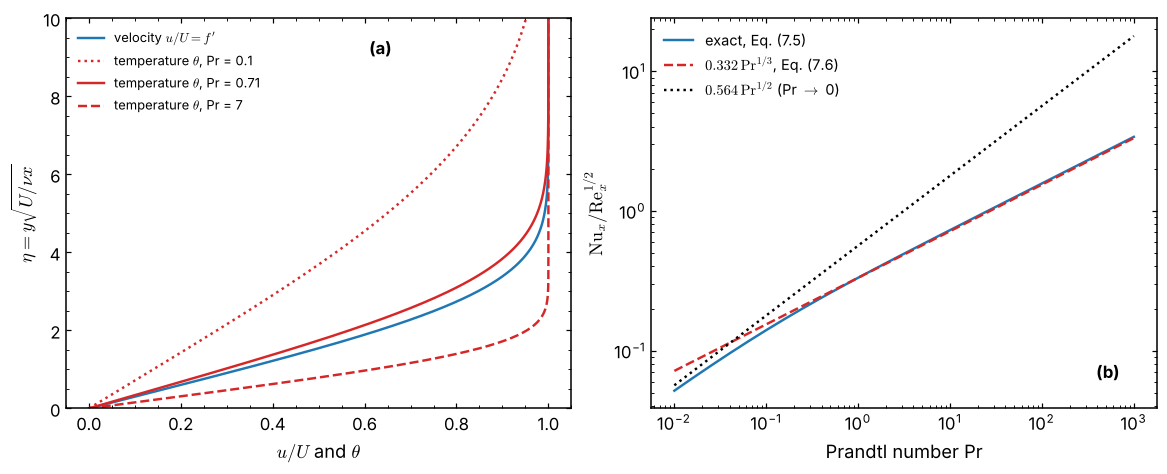

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax1.plot(bl["fp"], bl["eta"], "C0", label=r"velocity $u/U = f'$")
for Pr, style in ((0.1, ":"), (0.71, "-"), (7.0, "--")):
    sol = reference.similarity_bvp(Pr)
    eta_p = np.linspace(0, 10, 300)
    ax1.plot(sol["sol"].sol(eta_p)[3], eta_p, "C3" + style, label=rf"temperature $\theta$, Pr = {Pr:g}")
ax1.set_xlabel(r"$u/U$ and $\theta$")
ax1.set_ylabel(r"$\eta = y\sqrt{U/\nu x}$")
ax1.set_ylim(0, 10)
ax1.legend(loc="upper left", fontsize=8.5)
panel_label(ax1, "(a)", x=0.6)

ax2.loglog(Prs, exact, "C0", label="exact, Eq. (7.5)")
ax2.loglog(Prs, 0.332 * Prs ** (1 / 3), "C3--", label=r"$0.332\,\mathrm{Pr}^{1/3}$, Eq. (7.6)")
ax2.loglog(Prs, 0.564 * Prs ** 0.5, "k:", label=r"$0.564\,\mathrm{Pr}^{1/2}$ (Pr $\to$ 0)")
ax2.set_xlabel("Prandtl number Pr")
ax2.set_ylabel(r"$\mathrm{Nu}_x/\mathrm{Re}_x^{1/2}$")
ax2.legend(loc="upper left")
panel_label(ax2, "(b)", x=0.88, y=0.12)
plt.show()

**Figure 7.1.** (a) The Blasius velocity profile (7.3) and Pohlhausen temperature profiles
(7.4) for three Prandtl numbers, against the similarity variable. (b) The local heat
transfer of a laminar flat plate against Pr: the exact result (7.5), the fitted formula
(7.6), and the limit for small Pr.

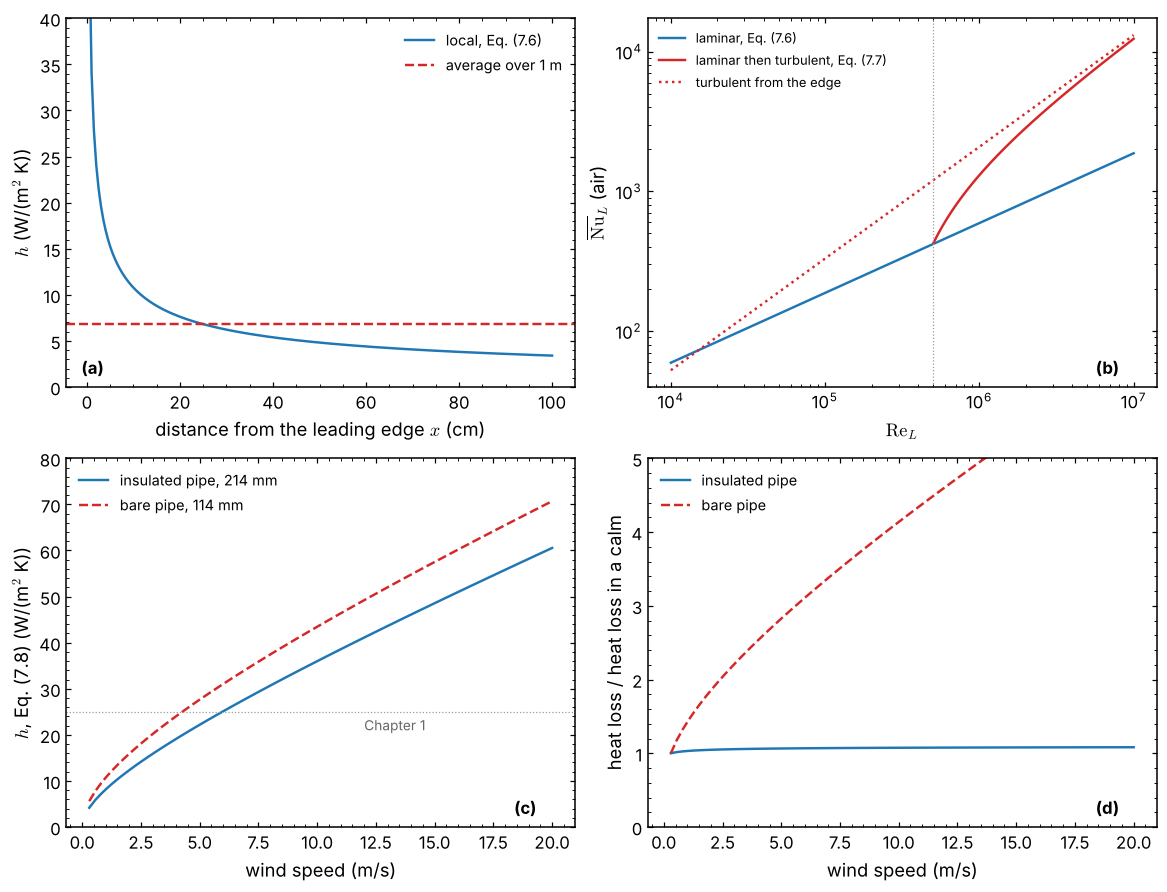

In [6]:
winds = np.linspace(0.3, 20, 80)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
xs = np.linspace(0.005, 1.0, 200)
U_plate = 3.0
air20 = properties.dry_air_properties(293.15)
h_local = 0.332 * air20["k"] / xs * np.sqrt(U_plate * xs / air20["nu"]) * air20["Pr"] ** (1 / 3)
ax.plot(xs * 100, h_local, "C0", label="local, Eq. (7.6)")
ax.axhline(2 * h_local[-1], color="C3", ls="--", label="average over 1 m")
ax.set_xlabel("distance from the leading edge $x$ (cm)")
ax.set_ylabel(r"$h$ (W/(m$^2$ K))")
ax.set_ylim(0, 40)
ax.legend(loc="upper right")
panel_label(ax, "(a)", y=0.08)

ax = axes[0, 1]
ReL = np.logspace(4, 7, 200)
lam = 0.664 * ReL**0.5 * 0.71 ** (1 / 3)
mixed = (0.037 * ReL**0.8 - 871) * 0.71 ** (1 / 3)
turb = 0.037 * ReL**0.8 * 0.71 ** (1 / 3)
ax.loglog(ReL, lam, "C0", label="laminar, Eq. (7.6)")
ax.loglog(ReL[ReL > 5e5], mixed[ReL > 5e5], "C3", label="laminar then turbulent, Eq. (7.7)")
ax.loglog(ReL, turb, "C3:", label="turbulent from the edge")
ax.axvline(5e5, color="0.6", lw=0.8, ls=":")
ax.set_xlabel(r"$\mathrm{Re}_L$")
ax.set_ylabel(r"$\overline{\mathrm{Nu}}_L$ (air)")
ax.legend(loc="upper left", fontsize=8.5)
panel_label(ax, "(b)", x=0.88, y=0.08)

ax = axes[1, 0]
ax.plot(winds, [h_wind(V, D_clad) for V in winds], "C0", label="insulated pipe, 214 mm")
ax.plot(winds, [h_wind(V, D_bare) for V in winds], "C3--", label="bare pipe, 114 mm")
ax.axhline(25, color="0.6", lw=0.8, ls=":")
ax.text(12, 21, "Chapter 1", fontsize=9, color="0.4")
ax.set_xlabel("wind speed (m/s)")
ax.set_ylabel(r"$h$, Eq. (7.8) (W/(m$^2$ K))")
ax.set_ylim(0, 80)
ax.legend(loc="upper left")
panel_label(ax, "(c)", x=0.88, y=0.08)

ax = axes[1, 1]
q_ins = np.array([heat_loss(V) for V in winds])
q_bare = np.array([heat_loss(V, False) for V in winds])
ax.plot(winds, q_ins / q_ins[0], "C0", label="insulated pipe")
ax.plot(winds, q_bare / q_bare[0], "C3--", label="bare pipe")
ax.set_xlabel("wind speed (m/s)")
ax.set_ylabel("heat loss / heat loss in a calm")
ax.set_ylim(0, 5)
ax.legend(loc="upper left")
panel_label(ax, "(d)", x=0.88, y=0.08)
plt.show()

**Figure 7.2.** (a) The local heat transfer coefficient along a flat plate in air at 3 m/s,
and its average over 1 m. (b) Average Nusselt number of a plate in air: laminar, laminar
then turbulent from $\mathrm{Re}_c = 5 \times 10^5$, and turbulent from the edge. (c) Heat
transfer coefficient of the pipe of Chapter 1 against the wind, insulated and bare, in air at
−35 °C. (d) Heat loss of the two pipes against the wind, relative to a calm of 0.3 m/s.

## 7.5 Checks

*Shooting against collocation.* `reference.similarity_bvp` solves Eqs. (7.3) and (7.4)
together with `scipy.integrate.solve_bvp`; the quadrature (7.5) and the shooting solution of
the package are compared with it over Pr from 0.01 to 1000.

*Similarity against marching.* `reference.boundary_layer_march` solves the boundary-layer
equations themselves, starting from a uniform flow near the leading edge and stepping
downstream, with nothing assumed about the shape of the profiles. If the similarity
solution is right, $C_{f,x}\mathrm{Re}_x^{1/2}$ and $\mathrm{Nu}_x/\mathrm{Re}_x^{1/2}$ from the
march must settle on the Blasius and Pohlhausen values.

*The limits.* For large Pr the exact result must approach $0.339\,\mathrm{Pr}^{1/3}$, and for
small Pr $0.564\,\mathrm{Pr}^{1/2}$ (the solution with $f = \eta$, uniform flow).

In [7]:
Pr_check = np.logspace(-2, 3, 11)
bvp = np.array([reference.similarity_bvp(Pr)["dtheta0"] for Pr in Pr_check])
quad = np.array([convection_ext.pohlhausen_heat_transfer(Pr, n_steps=8000) for Pr in Pr_check])
print(f"quadrature vs collocation: largest relative difference {np.max(np.abs(quad / bvp - 1)):.1e}")
fpp_bvp = reference.similarity_bvp(0.71)["fpp0"]
FPP0 = 0.33205733621519630                       # f''(0) computed to many digits (see Boyd, 2008)
steps = np.array([25, 50, 100, 200, 400])
fpp_err = np.array([abs(convection_ext.solve_blasius(10.0, n)["fpp0"] - FPP0) for n in steps])
print(f"shooting f''(0) with 2000 steps: {convection_ext.solve_blasius(10.0, 2000)['fpp0']:.8f},"
      f" collocation {fpp_bvp:.8f}")
print(f"large Pr: exact / (0.339 Pr^1/3) at Pr = 1000: {bvp[-1] / (0.339 * 1000 ** (1 / 3)):.4f};"
      f" small Pr: exact / (0.564 Pr^1/2) at Pr = 0.01: {bvp[0] / (0.564 * 0.01 ** 0.5):.4f}")

marches = {}
for n in (100, 200, 400):
    marches[n] = reference.boundary_layer_march(0.71, n_x=n, n_y=n // 2)
target_Nu = convection_ext.pohlhausen_heat_transfer(0.71)
for n, m in marches.items():
    print(f"marching with {n} steps: Cf Re^1/2 {m['Cf_sqrtRe'][-1]:.4f} (Blasius {2 * fpp_bvp:.4f}),"
          f" Nu/Re^1/2 {m['Nu_sqrtRe'][-1]:.4f} (Pohlhausen {target_Nu:.4f})")
cf_err = np.array([abs(m["Cf_sqrtRe"][-1] / (2 * fpp_bvp) - 1) for m in marches.values()])
print(f"order of the marching scheme: {-np.polyfit(np.log([100, 200, 400]), np.log(cf_err), 1)[0]:.2f}")

quadrature vs collocation: largest relative difference 3.6e-06


shooting f''(0) with 2000 steps: 0.33205734, collocation 0.33205734
large Pr: exact / (0.339 Pr^1/3) at Pr = 1000: 0.9991; small Pr: exact / (0.564 Pr^1/2) at Pr = 0.01: 0.9147


marching with 100 steps: Cf Re^1/2 0.6604 (Blasius 0.6641), Nu/Re^1/2 0.2940 (Pohlhausen 0.2942)
marching with 200 steps: Cf Re^1/2 0.6622 (Blasius 0.6641), Nu/Re^1/2 0.2941 (Pohlhausen 0.2942)
marching with 400 steps: Cf Re^1/2 0.6633 (Blasius 0.6641), Nu/Re^1/2 0.2942 (Pohlhausen 0.2942)
order of the marching scheme: 1.09


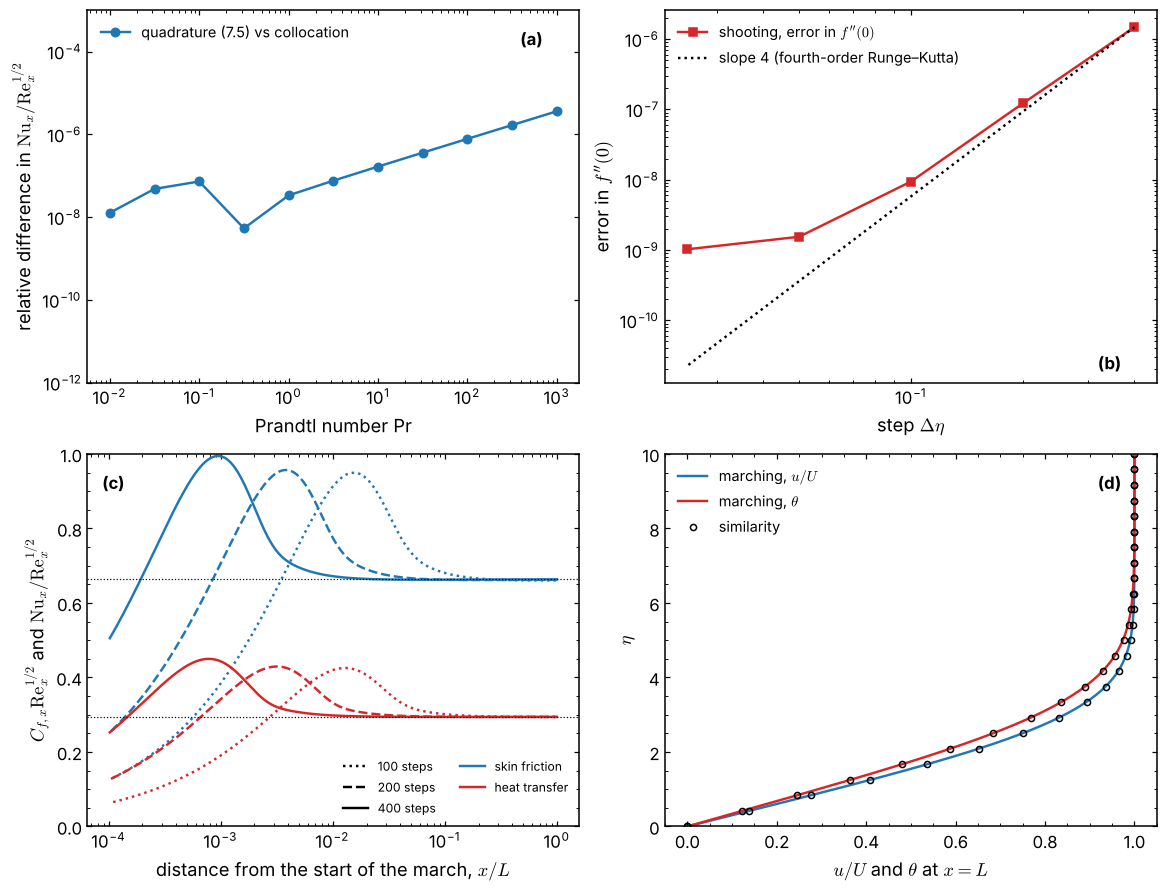

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
ax.loglog(Pr_check, np.abs(quad / bvp - 1), "o-", label="quadrature (7.5) vs collocation")
ax.set_xlabel("Prandtl number Pr")
ax.set_ylabel(r"relative difference in $\mathrm{Nu}_x/\mathrm{Re}_x^{1/2}$")
ax.set_ylim(1e-12, 1e-3)
ax.legend(loc="upper left")
panel_label(ax, "(a)", x=0.88)

ax = axes[0, 1]
ax.loglog(10.0 / steps, fpp_err, "s-", color="C3", label=r"shooting, error in $f''(0)$")
ax.loglog(10.0 / steps, fpp_err[0] * (steps[0] / steps) ** 4, "k:", label="slope 4 (fourth-order Runge–Kutta)")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r"step $\Delta\eta$")
ax.set_ylabel(r"error in $f''(0)$")
ax.legend(loc="upper left")
panel_label(ax, "(b)", x=0.88, y=0.08)

ax = axes[1, 0]
for (n, m), style in zip(marches.items(), (":", "--", "-")):
    ax.semilogx(m["x"], m["Cf_sqrtRe"], "C0" + style)
    ax.semilogx(m["x"], m["Nu_sqrtRe"], "C3" + style)
    ax.plot([], [], "k" + style, label=f"{n} steps")
ax.plot([], [], "C0", label="skin friction")
ax.plot([], [], "C3", label="heat transfer")
ax.axhline(2 * fpp_bvp, color="k", lw=0.8, ls=":")
ax.axhline(target_Nu, color="k", lw=0.8, ls=":")
ax.set_xlabel(r"distance from the start of the march, $x/L$")
ax.set_ylabel(r"$C_{f,x}\mathrm{Re}_x^{1/2}$ and $\mathrm{Nu}_x/\mathrm{Re}_x^{1/2}$")
ax.set_ylim(0, 1.0)
ax.legend(loc="lower right", fontsize=8, ncol=2)
panel_label(ax, "(c)")

ax = axes[1, 1]
m = marches[400]
ax.plot(m["u"], m["eta"], "C0", label="marching, $u/U$")
ax.plot(m["T"], m["eta"], "C3", label=r"marching, $\theta$")
sol = reference.similarity_bvp(0.71)["sol"]
eta_p = np.linspace(0, 10, 25)
ax.plot(sol.sol(eta_p)[1], eta_p, "ko", ms=4, mfc="none", label="similarity")
ax.plot(sol.sol(eta_p)[3], eta_p, "ko", ms=4, mfc="none")
ax.set_xlabel(r"$u/U$ and $\theta$ at $x = L$")
ax.set_ylabel(r"$\eta$")
ax.set_ylim(0, 10)
ax.legend(loc="upper left")
panel_label(ax, "(d)", x=0.88)
plt.show()

**Figure 7.3.** Checks. (a) Difference between the quadrature (7.5) and the collocation
solution of Eqs. (7.3)–(7.4), against Pr. (b) Error of the shooting solution of the
package in $f''(0)$ against the step, measured from the value known to many digits; the
dotted line has slope 4. (c) Skin friction and heat
transfer from the marching solution, which starts from a uniform flow, against distance,
for three numbers of steps; the dotted lines are the similarity values. (d) Velocity and
temperature profiles at the end of the march and from the similarity solution, Pr = 0.71.

The quadrature and the collocation agree to $4 \times 10^{-6}$ or better over five decades of Pr, and
the shooting converges at the fourth order of its Runge–Kutta steps until, near
$10^{-9}$, it meets the error of stopping the integration at $\eta = 10$. The marching
solution forgets its uniform start within a short distance and settles on the Blasius and
Pohlhausen values, its error falling as the first power of its step, as expected for
backward steps; its profiles at the end of the plate fall on the similarity profiles. The
large-Pr limit holds to 0.1 % at Pr = 1000; the small-Pr limit is approached slowly, and is
still 9 % above the exact result at Pr = 0.01.

## 7.6 What to trust

* *The exact solutions* are exact for a smooth plate, a steady laminar stream with no
  pressure gradient and constant properties. Real plates and outdoor winds rarely give a
  laminar layer more than a few tens of centimetres long.
* *Correlations* such as Eq. (7.8) fit experiments to about ±20 %. Turbulence in the
  approaching wind, roughness, neighbouring buildings and the direction of the wind all
  matter, and they are not in the formula.
* *For design*, this uncertainty matters only where the outer film controls the heat flow.
  For the insulated pipe it changes nothing; for a bare pipe, a person or a window, it is the
  answer.

## Summary

* A boundary layer grows as $\delta/x \sim \mathrm{Re}_x^{-1/2}$, Eq. (7.1); the thermal layer
  is $\mathrm{Pr}^{-1/3}$ times as thick for Pr of order one or more, and $h \sim k/\delta_T$,
  Eq. (7.2).
* Blasius's equation (7.3) and Pohlhausen's (7.4) are exact for a laminar flat plate; the
  heat transfer is the quadrature (7.5), fitted by $\mathrm{Nu}_x = 0.332\,\mathrm{Re}_x^{1/2}
  \mathrm{Pr}^{1/3}$, Eq. (7.6).
* Turbulent layers transfer much more heat, Eq. (7.7); a cylinder in cross flow is
  described by the Churchill–Bernstein correlation, Eq. (7.8).
* The $h = 25$ W/(m² K) of Chapter 1 is a 6 m/s wind; the wind barely changes the loss of
  an insulated pipe but multiplies that of a bare one several times.

## Exercises

Sample solutions are in [`solutions/part2_convection/07_solutions.ipynb`](../../solutions/part2_convection/07_solutions.ipynb).

1. **Wind chill.** A face is roughly a cylinder 0.18 m across. Heat reaches its surface
   from the body at 34 °C through tissue with a resistance of about 0.1 m² K/W. Find the
   heat lost per square metre and the temperature of the skin in air at −20 °C, at walking
   speed (1.34 m/s) and in winds of 5 and 15 m/s. At what air temperature would a person
   walking in calm air lose heat from the face as fast as at −20 °C in the two winds? This
   is the idea behind the wind-chill index.
2. **A solar panel.** A photovoltaic panel 1.6 m long (in the direction of the wind) and
   1 m wide sits in air at 20 °C with a 3 m/s breeze along it, and absorbs 700 W/m² of
   sunlight, of which 20 % becomes electricity. Ignoring radiation and the back face, find
   its temperature with a laminar layer, with a layer turbulent from the edge, and with the
   mixed formula (7.7). Which would you trust outdoors?
3. **Liquid metal.** Liquid sodium ($\mathrm{Pr} = 0.005$) flows along a plate. Compare the
   heat transfer from the exact quadrature (7.5), from Eq. (7.6), and from the small-Pr limit
   $0.564\,\mathrm{Re}_x^{1/2}\mathrm{Pr}^{1/2}$. Explain the result with the scaling of
   Section 7.1.
4. **An unheated starting length.** If the plate is heated only beyond $x_0$, the classical
   result is $\mathrm{Nu}_x = 0.332\,\mathrm{Re}_x^{1/2}\mathrm{Pr}^{1/3}
   [1 - (x_0/x)^{3/4}]^{-1/3}$. Use `reference.boundary_layer_march` with
   `x_heat_start=0.3`, so that the wall stays at the stream temperature for $x < 0.3L$, and
   compare. Why is the heat transfer so large just after the heating starts?

## Suggested references

* H. Blasius, "Grenzschichten in Flüssigkeiten mit kleiner Reibung", *Z. Math. Phys.* **56**,
  1 (1908).
* E. Pohlhausen, "Der Wärmeaustausch zwischen festen Körpern und Flüssigkeiten mit kleiner
  Reibung und kleiner Wärmeleitung", *Z. Angew. Math. Mech.* **1**, 115 (1921).
* S. W. Churchill and M. Bernstein, "A correlating equation for forced convection from
  gases and liquids to a circular cylinder in crossflow", *J. Heat Transfer* **99**, 300
  (1977).
* H. Schlichting and K. Gersten, *Boundary-Layer Theory*, 9th ed. (Springer, 2017).
* J. P. Boyd, "The Blasius function: computations before computers, the value of tricks,
  undergraduate projects, and open research problems", *SIAM Rev.* **50**, 791 (2008).

---

**Previous:** [6. Semi-infinite solids and phase change](../part1_conduction/06_semi_infinite.ipynb) &nbsp;·&nbsp; **Next:** [8. Internal flow and the Graetz problem](08_internal_flow.ipynb)